In [29]:
# import des bibliothèques nécessaires
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


In [30]:
# Récupération du dataset
df = pd.read_csv('data/df_clean.csv')
df.head()

,OSEBuildingID,BuildingType,PrimaryPropertyType,PropertyName,Address,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,...,SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity
0,1,NonResidential,Hotel,Mayflower park hotel,405 Olive way,0659000030,7,DOWNTOWN,47.61220,-122.33799,...,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,249.98,2.83
1,2,NonResidential,Hotel,Paramount Hotel,724 Pine street,0659000220,7,DOWNTOWN,47.61317,-122.33393,...,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,295.86,2.86
2,3,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,0659000475,7,DOWNTOWN,47.61393,-122.33810,...,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,2089.28,2.19
3,5,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,0659000640,7,DOWNTOWN,47.61412,-122.33664,...,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,286.43,4.67
4,8,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,0659000970,7,DOWNTOWN,47.61375,-122.34047,...,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,505.01,2.88


# Exploration du dataset nettoyé

In [31]:
# information sur les données et les types

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1542 entries, 0 to 1541
Data columns (total 37 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    1542 non-null   int64  
 1   BuildingType                     1542 non-null   str    
 2   PrimaryPropertyType              1542 non-null   str    
 3   PropertyName                     1542 non-null   str    
 4   Address                          1542 non-null   str    
 5   TaxParcelIdentificationNumber    1542 non-null   str    
 6   CouncilDistrictCode              1542 non-null   int64  
 7   Neighborhood                     1542 non-null   str    
 8   Latitude                         1542 non-null   float64
 9   Longitude                        1542 non-null   float64
 10  YearBuilt                        1542 non-null   int64  
 11  NumberofBuildings                1542 non-null   float64
 12  NumberofFloors                 

In [32]:
# Informations statistiques sur les colonnes numériques

df.describe()

,OSEBuildingID,CouncilDistrictCode,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),...,SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity
count,1542.000000,1542.000000,1542.000000,1542.000000,1542.000000,1542.000000,1526.000000,1.542000e+03,1542.000000,1.542000e+03,...,1542.000000,1.542000e+03,1.541000e+03,1.542000e+03,1.542000e+03,1.542000e+03,1.542000e+03,1.542000e+03,1542.000000,1542.000000
mean,16470.426719,4.415045,47.616487,-122.333523,1961.588846,1.142023,4.262123,1.152784e+05,13872.791829,1.014056e+05,...,185.607588,8.024914e+06,8.156507e+06,4.982141e+05,1.652264e+06,5.637525e+06,1.852867e+04,1.852867e+06,176.163366,1.650415
std,13789.438674,2.192603,0.046978,0.023265,32.838734,1.182804,6.368218,1.978206e+05,43796.081781,1.753431e+05,...,188.065920,1.928942e+07,1.952623e+07,5.310227e+06,3.885019e+06,1.325569e+07,6.148985e+04,6.148985e+06,592.219483,2.265110
min,1.000000,1.000000,47.509590,-122.411820,1900.000000,1.000000,1.000000,1.128500e+04,0.000000,3.636000e+03,...,0.000000,5.713320e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.400000,0.010000
25%,602.250000,2.000000,47.587825,-122.343093,1930.000000,1.000000,1.000000,2.882525e+04,0.000000,2.791425e+04,...,84.674999,1.248602e+06,1.322417e+06,0.000000e+00,2.144374e+05,7.316600e+05,0.000000e+00,0.000000e+00,20.685000,0.360000
50%,21180.500000,4.000000,47.612615,-122.333170,1965.000000,1.000000,2.000000,4.806600e+04,0.000000,4.602500e+04,...,141.849998,2.727768e+06,2.824097e+06,0.000000e+00,5.109501e+05,1.743362e+06,4.910975e+03,4.910975e+05,49.940000,0.885000
75%,24603.750000,7.000000,47.649080,-122.322823,1988.000000,1.000000,4.000000,1.073940e+05,0.000000,9.530650e+04,...,215.674999,7.271161e+06,7.456910e+06,0.000000e+00,1.542024e+06,5.261384e+06,1.531061e+04,1.531061e+06,147.105000,1.960000
max,50226.000000,7.000000,47.733870,-122.261800,2015.000000,27.000000,76.000000,2.200000e+06,512608.000000,2.200000e+06,...,2620.000000,2.930908e+08,2.966717e+08,1.349435e+08,8.046087e+07,2.745325e+08,1.381912e+06,1.381912e+08,12307.160000,25.710000


In [33]:
# Informations sur les colonnes non numériques

df.describe(exclude=[np.number])

,BuildingType,PrimaryPropertyType,PropertyName,Address,TaxParcelIdentificationNumber,Neighborhood,ListOfAllPropertyUseTypes,LargestPropertyUseType,SecondLargestPropertyUseType,ThirdLargestPropertyUseType
count,1542,1542,1542,1542,1542,1542,1542,1542,1542,1542
unique,5,20,1538,1521,1463,13,366,55,48,40
top,NonResidential,Small- and Mid-Sized Office,South Park,2600 SW Barton St,1625049001,DOWNTOWN,Office,Office,Aucun,Aucun
freq,1429,285,2,4,7,350,131,484,703,1197



ListOfAllPropertyUseTypes est comme son nom l'indique, une liste. 
Sachant que certaines informations de cette liste sont reprise dans les colonnes LargestPropertyUseType/SecondLargestPropertyUseType/ThirdLargestPropertyUseType, on peut modifier la liste en colonne numérique en la remplacant pas le nombre de types dans la liste 

In [34]:
# Remplacement de la liste par le nombre de types
df["ListOfAllPropertyUseTypes"] = df["ListOfAllPropertyUseTypes"].apply(lambda x : len(x.split(",")))

On retrouve des colonnes avec une forte cardinalité, c'est à dire avec quasiment autant de valeurs uniques que de lignes. 

Ce sont des colonnes identifiantes mais qui n'apportent pas d'intéret prédictive pour le modèle. 
En règle générale, il est préférable de supprimer les colonnes qui sont uniquement identifiantes et qui ne possèdent pas de réelle valeur prédictive.

In [35]:
# Suppression des colonnes à forte cardinalité
df = df.drop(columns = ["PropertyName","Address","TaxParcelIdentificationNumber"])

df.head()


,OSEBuildingID,BuildingType,PrimaryPropertyType,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,...,SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity
0,1,NonResidential,Hotel,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12.0,...,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,249.98,2.83
1,2,NonResidential,Hotel,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11.0,...,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,295.86,2.86
2,3,NonResidential,Hotel,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41.0,...,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,2089.28,2.19
3,5,NonResidential,Hotel,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10.0,...,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,286.43,4.67
4,8,NonResidential,Hotel,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18.0,...,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,505.01,2.88


les information qu'on ne pourra pas avoir sans relevés détaillés des propriétés 
On ne veut pas entraîner nos modèles dessus car on n'aura pas ces informations --> à drop:

 SiteEUI(kBtu/sf) -
  SiteEUIWN(kBtu/sf) -
 SourceEUI(kBtu/sf) -
 SourceEUIWN(kBtu/sf) -
 SiteEnergyUseWN(kBtu) -
 SteamUse(kBtu) -
 Electricity(kWh) -
 Electricity(kBtu) -
 NaturalGas(therms) -
 NaturalGas(kBtu) -              
 GHGEmissionsIntensity          



In [36]:
# Suppression des colonnes ayant de l'information énergétique : 
df = df.drop(columns=['SiteEUI(kBtu/sf)','SiteEUIWN(kBtu/sf)','SiteEnergyUseWN(kBtu)', 'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)', 'GHGEmissionsIntensity','SteamUse(kBtu)','Electricity(kWh)', 'Electricity(kBtu)','NaturalGas(therms)','NaturalGas(kBtu)'])

df.head()

,OSEBuildingID,BuildingType,PrimaryPropertyType,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,...,ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions
0,1,NonResidential,Hotel,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12.0,...,1,Hotel,88434.0,Aucun,0.0,Aucun,0.0,60.0,7226362.5,249.98
1,2,NonResidential,Hotel,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11.0,...,3,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,61.0,8387933.0,295.86
2,3,NonResidential,Hotel,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41.0,...,1,Hotel,756493.0,Aucun,0.0,Aucun,0.0,43.0,72587024.0,2089.28
3,5,NonResidential,Hotel,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10.0,...,1,Hotel,61320.0,Aucun,0.0,Aucun,0.0,56.0,6794584.0,286.43
4,8,NonResidential,Hotel,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18.0,...,3,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,75.0,14172606.0,505.01


<Axes: >

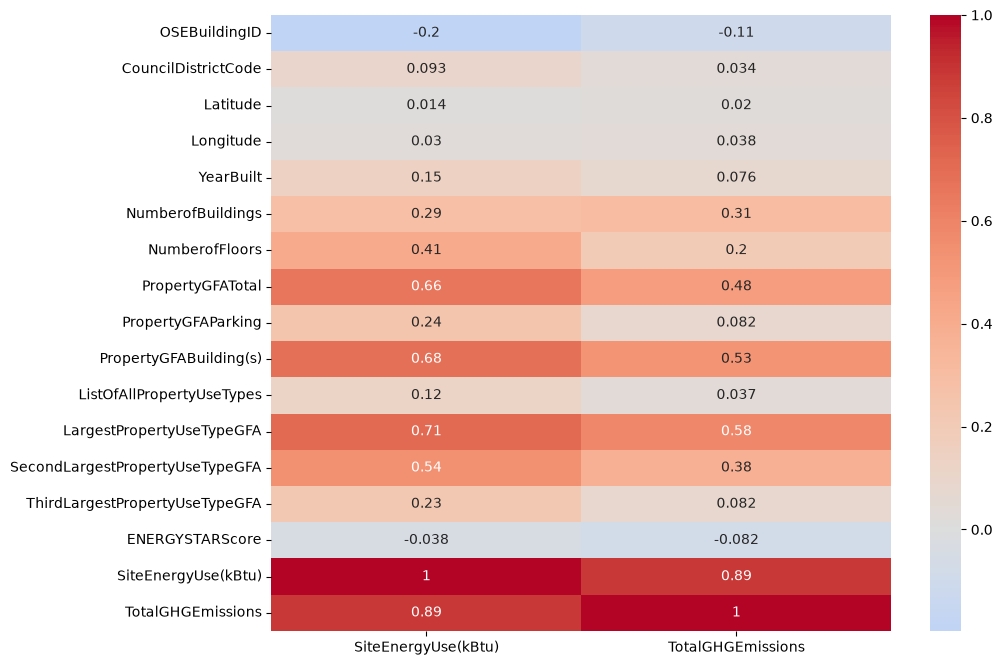

In [37]:
# détermination de la corrélation entre les colonnes numériques et les colonnes SiteEnergyUse(kBtu) et TotalGHGEmissions

corr_matrix = df.select_dtypes(include=['float64', 'int64']).corr()[['SiteEnergyUse(kBtu)','TotalGHGEmissions']]

# Visualisation de la corrélation
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)

Colonnes avec une corrélation modérée à forte (>0.4) avec SiteEnergyUse(kBtu): 

    - (NumberOfBuildings)
    - (NumberOfFloors)
    - PropertyGFATotal
    - PropertyGFABuilding(s)
    - LargestPropertyUseTypeGFA
    - SecondLargestPropertyUseTypeGFA

TotalGHGEEmissions et SiteEnergyUse sont les cibles à prédire donc on ne les prends pas en compte.

Le ENERGYSTARScore n'a pas une corrélation importante mais le but est aussi de voir son importance alors on peu la garder pour l'instant

Le YearBuilt a une faible corrélation car il s'agit on recherche une consommation d'énergie et émissions totales, et non pas par rapport à la surface des bâtiments. Sachant que nous avons dans notre dataset également la surface, il peut être intéressant de garder cette colonne pour voir son influence

PropertyGFATotal concerne les bâtiments et les parkings, et PropertyGFABuilding(s) uniquement les bâtiments. Sachant que les parkings ne consomment pas beaucoup d'énergie et présentent une corrélation faible, et que PropertyGFABuilding(s) et PropertyGFATotal sont donc très proches, il serait judicieux de n'en garder qu'une des 2 pour éviter le phénomène de multicolinéarité

Malgré la transformation ListOfAllPropertyUseTypes, il ne semble pas y avoir de corrélation entre cette colonnes et nos cibles


In [38]:
columns_to_drop = [
    "OSEBuildingID",
    "CouncilDistrictCode",
    "Latitude",
    "Longitude",
    "PropertyGFATotal",
    "PropertyGFAParking",
    "ListOfAllPropertyUseTypes"
]

df = df.drop(columns=columns_to_drop)

df.head()

,BuildingType,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions
0,NonResidential,Hotel,DOWNTOWN,1927,1.0,12.0,88434,Hotel,88434.0,Aucun,0.0,Aucun,0.0,60.0,7226362.5,249.98
1,NonResidential,Hotel,DOWNTOWN,1996,1.0,11.0,88502,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,61.0,8387933.0,295.86
2,NonResidential,Hotel,DOWNTOWN,1969,1.0,41.0,759392,Hotel,756493.0,Aucun,0.0,Aucun,0.0,43.0,72587024.0,2089.28
3,NonResidential,Hotel,DOWNTOWN,1926,1.0,10.0,61320,Hotel,61320.0,Aucun,0.0,Aucun,0.0,56.0,6794584.0,286.43
4,NonResidential,Hotel,DOWNTOWN,1980,1.0,18.0,113580,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,75.0,14172606.0,505.01


# Visualisations

In [ ]:
# Visualisations des relations des valeurs numérques dans notre df

sns.pairplot(df)

plt.show()

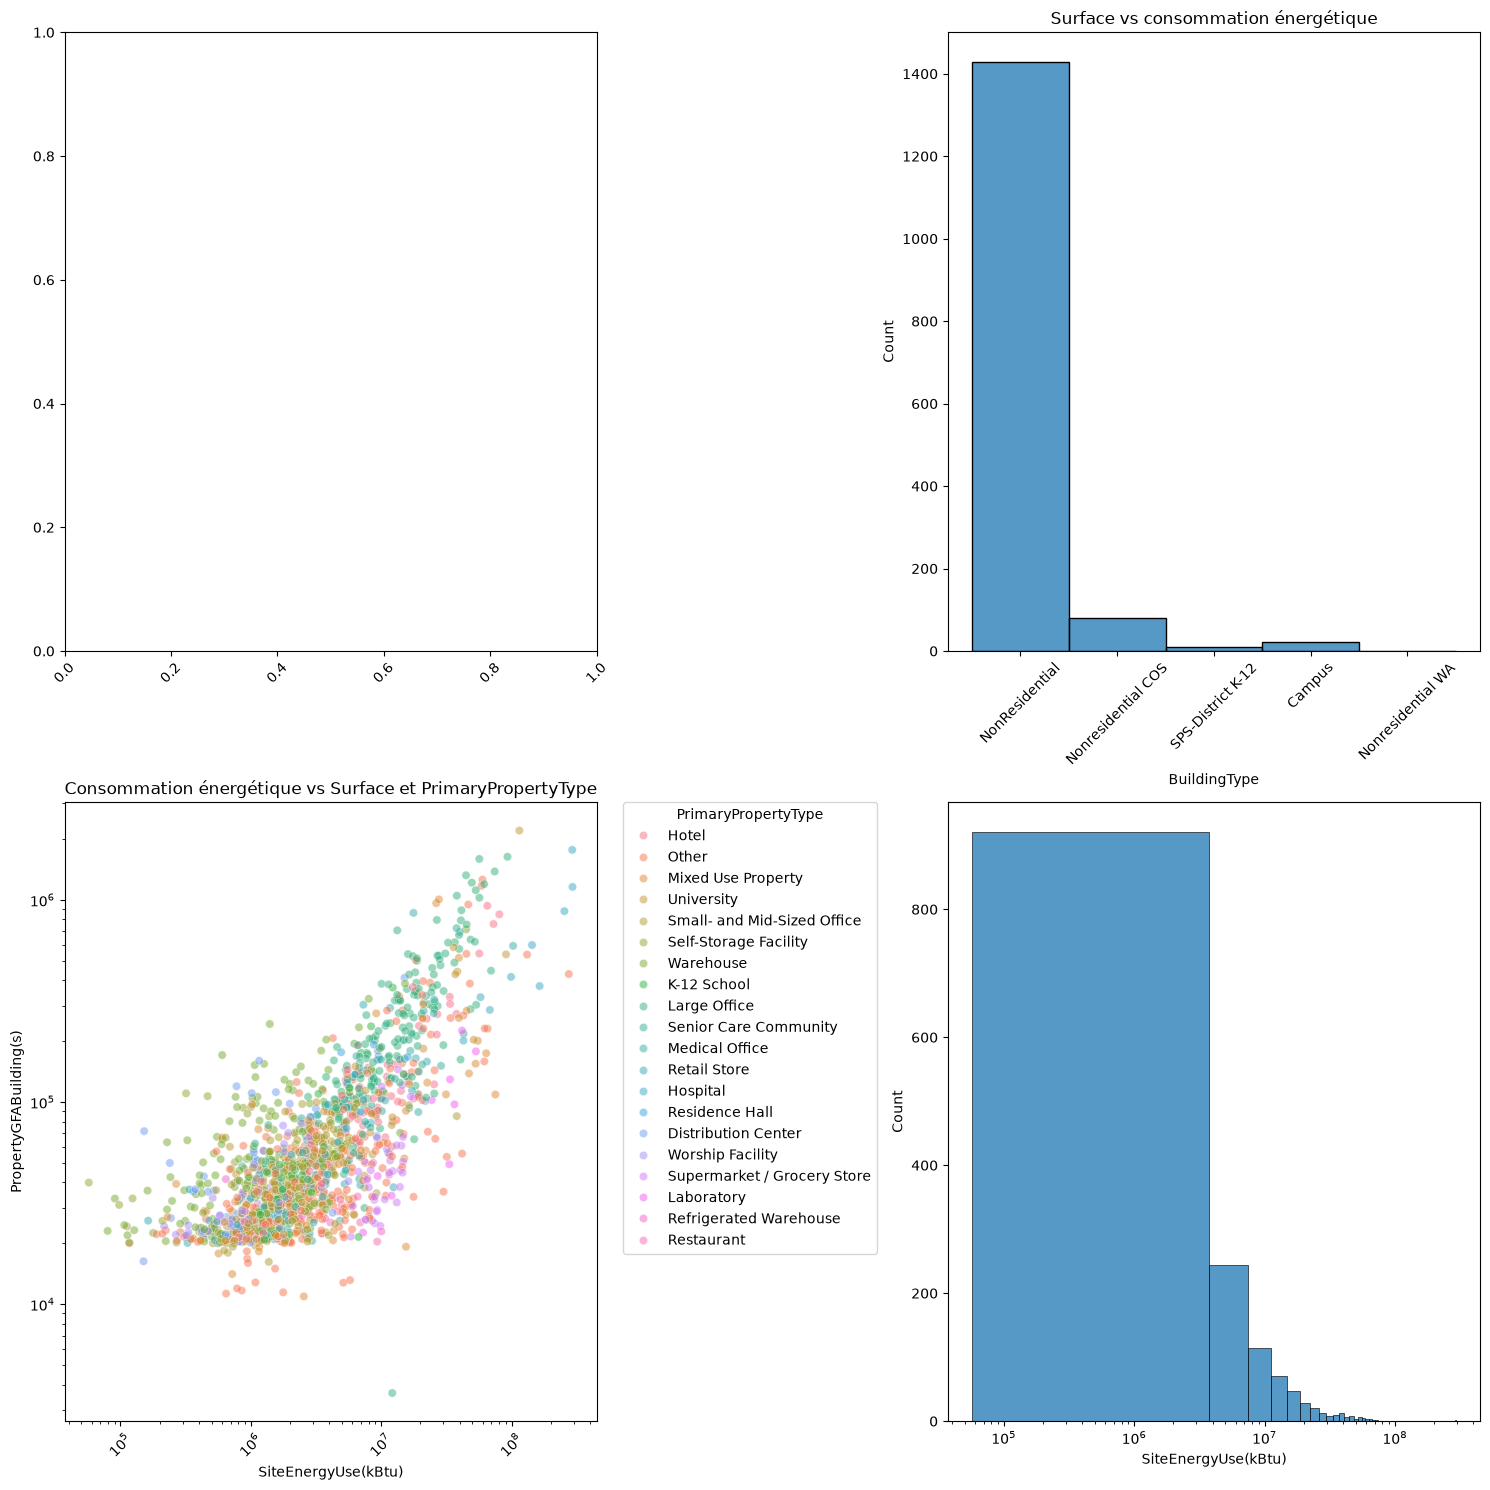

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(15, 15))

# Graphique 1 : Consommation énergétique selon la localisation géographique


# Graphique 2 : Distribution des building types
sns.histplot(
    data=df,
    x='BuildingType',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Building types')
axes[0, 1].set_title('Surface vs consommation énergétique')

# Graphique 3 : Energie, surface et Type de batiment
sns.scatterplot(
    data=df,
    x='SiteEnergyUse(kBtu)',
    y='PropertyGFABuilding(s)',
    hue = 'PrimaryPropertyType',
    ax=axes[1, 0],
    alpha=0.5
)
axes[1, 0].set_xscale('log')
axes[1, 0].set_yscale('log')
axes[1, 0].set_title('Consommation énergétique vs Surface et PrimaryPropertyType')
axes[1, 0].legend(title='PrimaryPropertyType',bbox_to_anchor=(1.05, 1),loc='upper left',borderaxespad=0)

# Graphique 4 : Energie, surface et Type de batiment
sns.histplot(
    data=df,
    x='SiteEnergyUse(kBtu)',
    ax=axes[1, 1]
)
axes[1, 1].set_xscale('log')

axes[0, 0].tick_params(axis='x', labelrotation=45)
axes[0, 1].tick_params(axis='x', labelrotation=45)
axes[1, 0].tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Moyenne des Emissions GES par ListOfAllPropertyUseTypes')

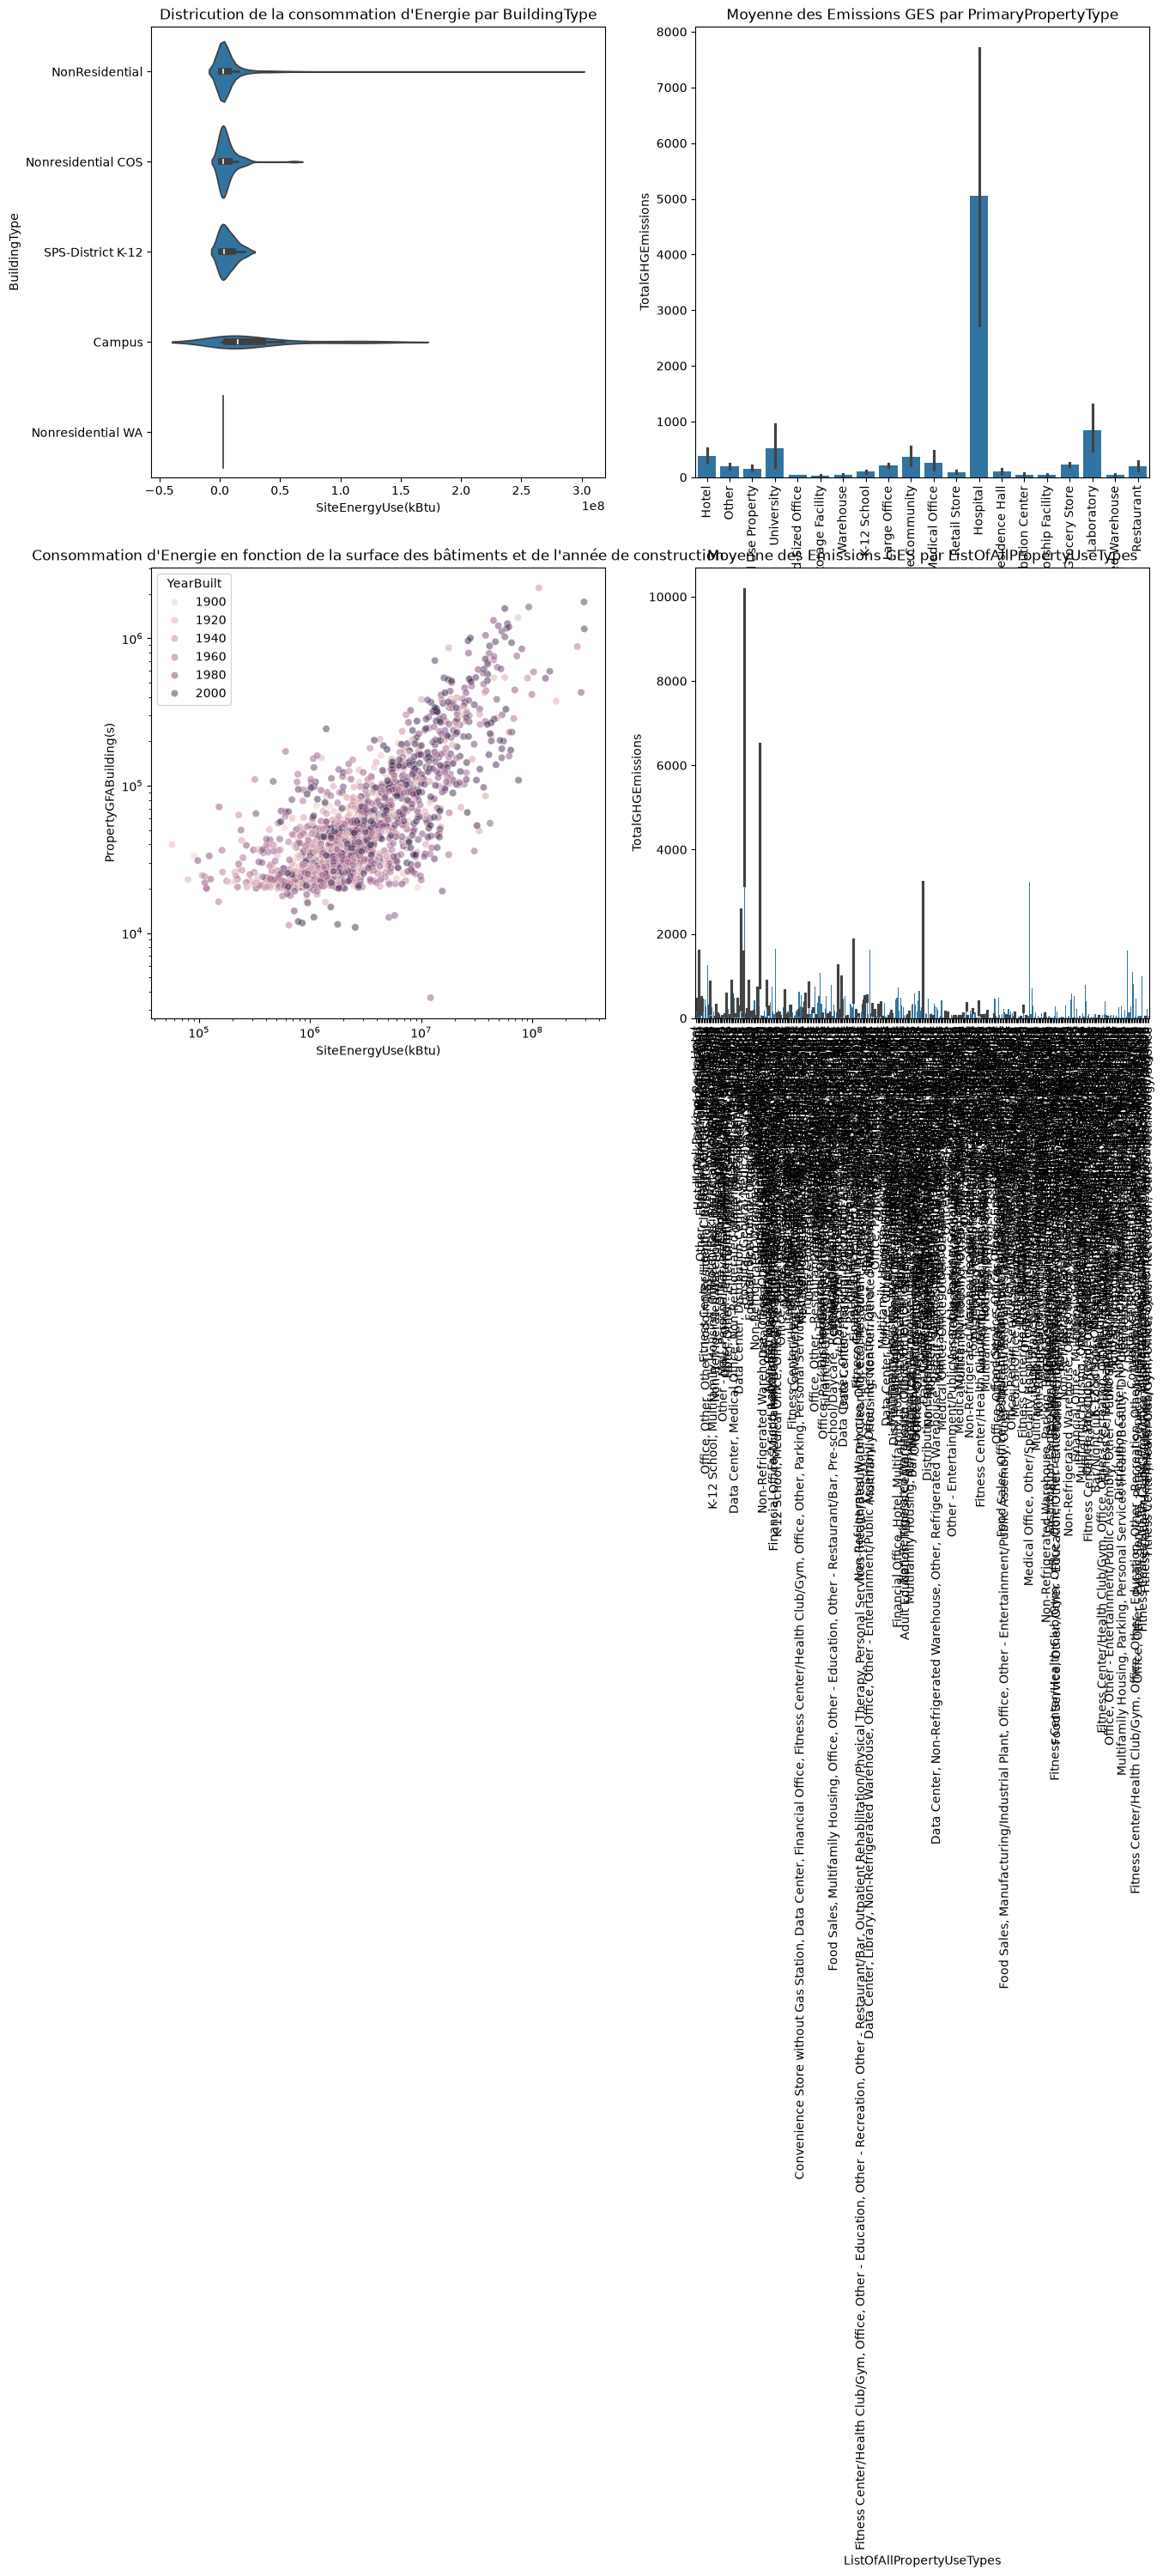

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(15, 15))

sns.violinplot(data=df, x = 'SiteEnergyUse(kBtu)' , y= 'BuildingType', ax=axes[0, 0] )
axes[0,0].set_title("Districution de la consommation d'Energie par BuildingType")

sns.barplot(data=df, x = 'PrimaryPropertyType' , y = 'TotalGHGEmissions', ax=axes[0, 1] )
axes[0, 1].tick_params(axis='x', labelrotation=90)
axes[0,1].set_title("Moyenne des Emissions GES par PrimaryPropertyType")

sns.scatterplot(data=df, x = 'SiteEnergyUse(kBtu)' , y = 'PropertyGFABuilding(s)', hue = 'YearBuilt', alpha = 0.5, ax=axes[1,0])
axes[1,0].set_title("Consommation d'Energie en fonction de la surface des bâtiments et de l'année de construction")
axes[1,0].set_xscale('log')
axes[1,0].set_yscale('log')

sns.barplot(data=df, x = 'ListOfAllPropertyUseTypes' , y = 'TotalGHGEmissions', ax=axes[1, 1] )
axes[1, 1].tick_params(axis='x', labelrotation=90)
axes[1,1].set_title("Moyenne des Emissions GES par ListOfAllPropertyUseTypes")

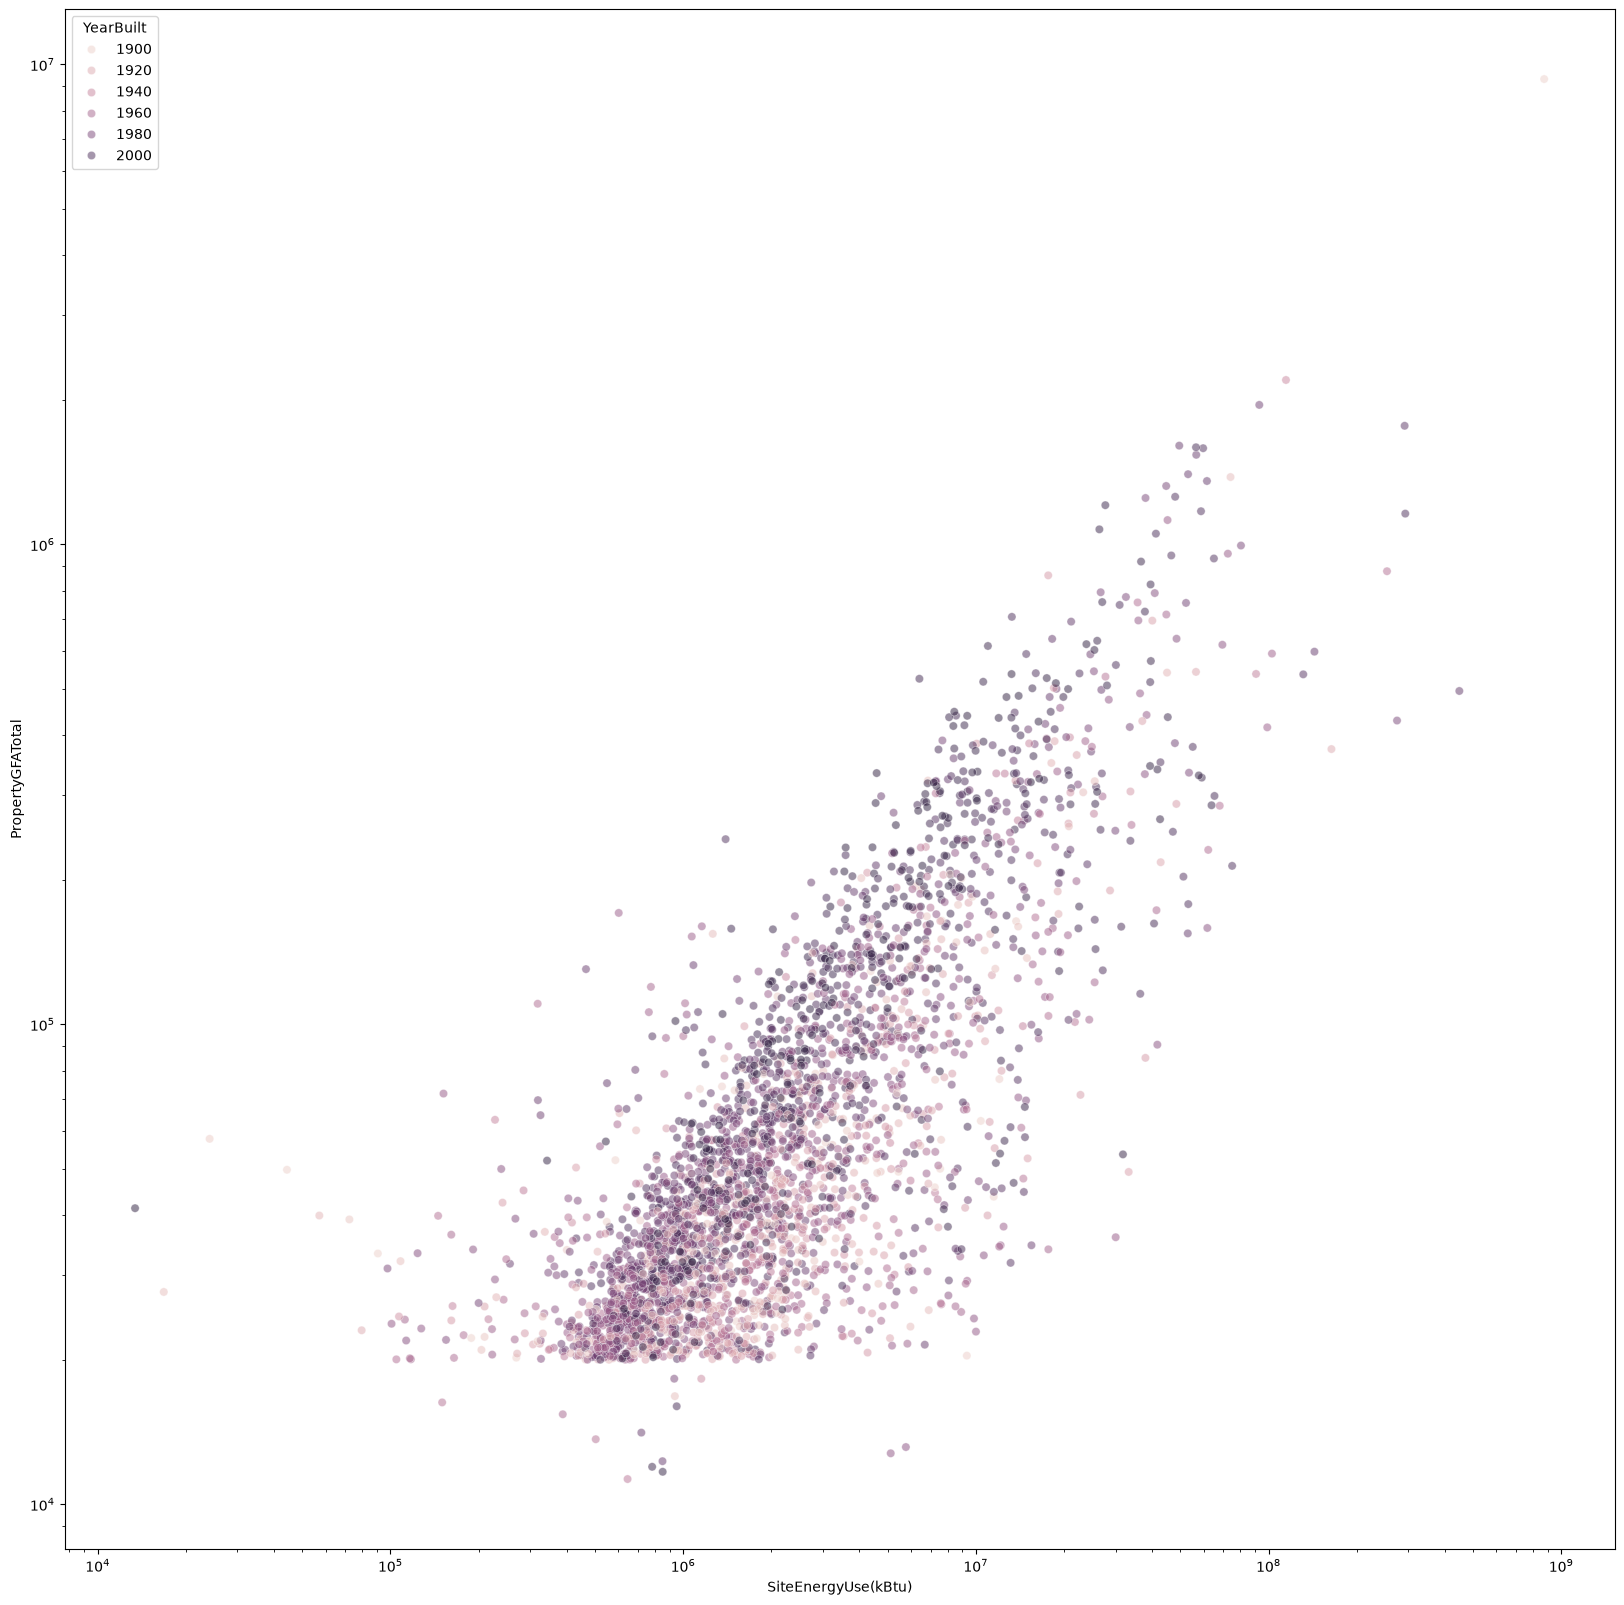

In [15]:
plt.figure(figsize=(20,20))

ax =sns.scatterplot(
    data=df,
    x='SiteEnergyUse(kBtu)',
    y='PropertyGFATotal',
    hue = 'YearBuilt',
    alpha=0.5
)
ax.set_xscale('log')
ax.set_yscale('log')

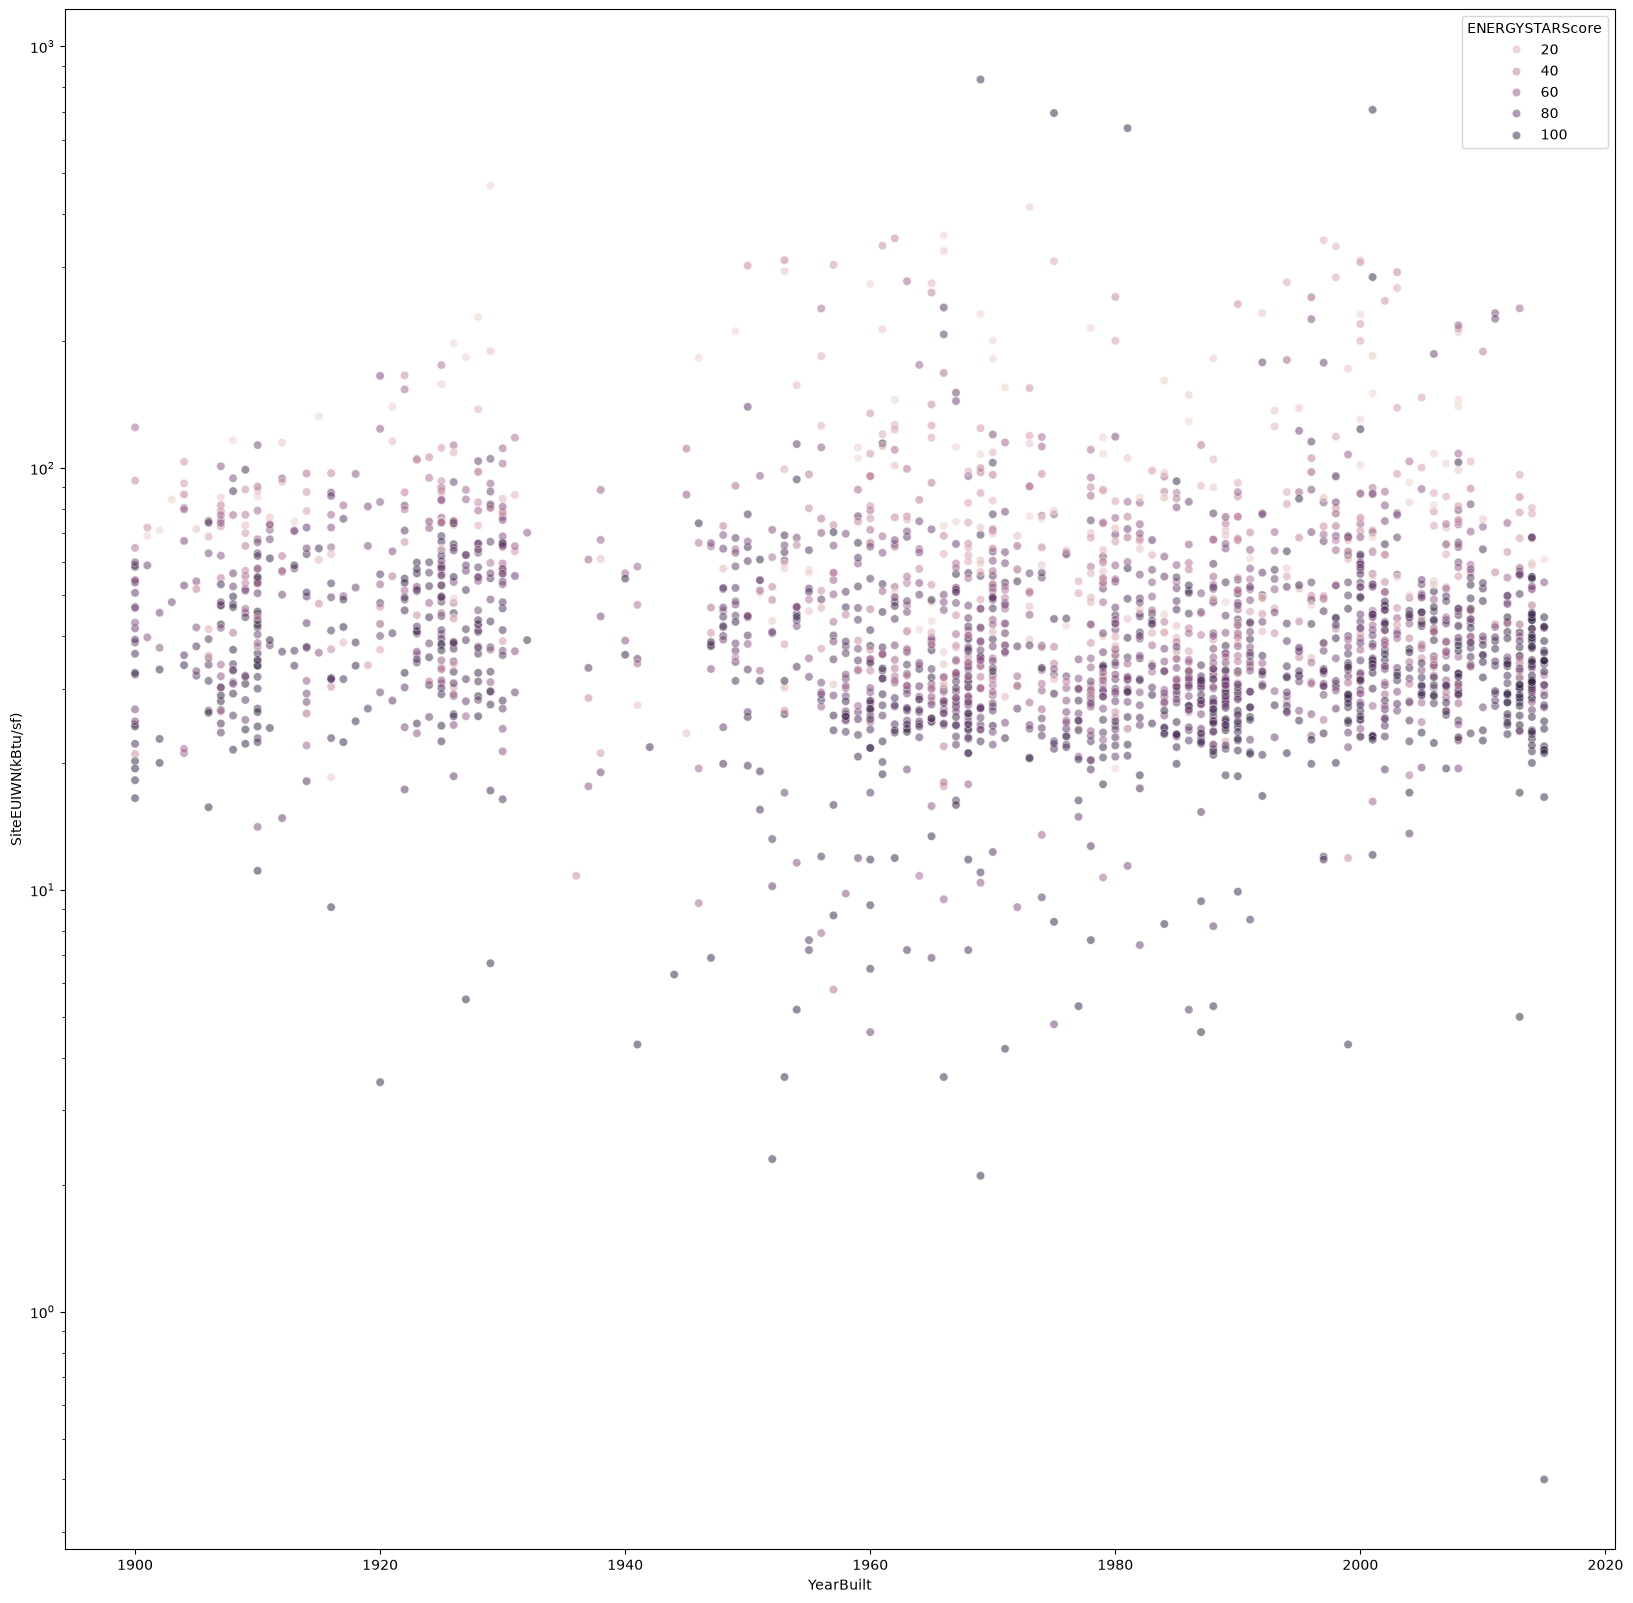

In [16]:
plt.figure(figsize=(20,20))

ax =sns.scatterplot(
    data=df,
    x='YearBuilt',
    y='SiteEUIWN(kBtu/sf)',
    hue = 'ENERGYSTARScore',
    alpha=0.5
)
ax.set_yscale('log')

Quelques conclusions : 

- Il y a des types de bâtiments autre que non-résidentiels dans le dataset --> supprimer les lignes "multifamily

- Il a des valeurs énergétiques à 0 --> à vérifier

- Il y a quelques outliers niveau consommation d'énergie qui remontent la moyenne fortement ( > 4.10^8 kBtu ) --> A supprimer ?

- Zipcode / Neigborhood / CouncilDistricCode , il n'y a pas vraiment de clusters bien définis qui se dégagent

- Year built semble avoir une légère corrélaton, pas directement avec la totalité de l'énergie mais l'énergie par la surface. 
    


In [17]:
# check des valeurs énergétiques nulles
df_tri3[df_tri3['SiteEnergyUse(kBtu)'] <= 0]

# On remarque que les valeurs nulles correspondent à une ComplianceStatus de "Missing Data"

,OSEBuildingID,BuildingType,PrimaryPropertyType,PropertyName,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,...,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEnergyUse(kBtu),DefaultData,ComplianceStatus,Outlier,TotalGHGEmissions
28,34,SPS-District K-12,K-12 School,Meany Building,301/300 21st Ave. E.,98112.0,0688000090,3,Central,47.62266,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,0.00
31,37,SPS-District K-12,K-12 School,John Hay Elementary,201 Garfield St.,98109.0,0809000005,7,MAGNOLIA / QUEEN ANNE,47.63290,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,10.43
62,87,SPS-District K-12,K-12 School,Arbor Heights Elementary,3701 S.W. 104th St.,98146.0,2518400005,1,SOUTHWEST,47.50970,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,4.19
81,118,SPS-District K-12,K-12 School,Pathfinder K-8,1901 SW Genesee St.,98106.0,1324039116,1,DELRIDGE,47.56360,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,11.84
85,122,SPS-District K-12,K-12 School,John Muir Elementary,3301 S. Horton St.,98144.0,1524049002,2,SOUTHEAST,47.57324,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,16.36
95,140,SPS-District K-12,K-12 School,B.F. Day Elementary,3921 Linden Ave. N.,98103.0,1931301145,6,LAKE UNION,47.65464,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,14.67
133,217,SPS-District K-12,K-12 School,Whitman Middle,9201 15th Ave. NW.,98117.0,3526039131,6,BALLARD,47.69675,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,229.38
139,227,SPS-District K-12,K-12 School,Washington Middle,2101 S. Jackson,98144.0,3646100540,3,CENTRAL,47.59796,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,170.90
152,242,SPS-District K-12,K-12 School,Olympic View Elementary,504 N.E. 95th St.,98115.0,5100404840,5,NORTH,47.69823,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,0.00
304,435,NonResidential,Other,Washington State Convention Center,705 Pike St,98101.0,1978200105,7,DOWNTOWN,47.61195,...,686750.0,NaN,NaN,NaN,NaN,0.0,False,Non-Compliant,No outlier,0.00


In [18]:
# Quantité de valeurs par ComplianceStatus --> on peut supprimer les lignes avec "Missing Data"
df_tri3["ComplianceStatus"].value_counts()

ComplianceStatus
Compliant                       3211
Error - Correct Default Data     113
Non-Compliant                     37
Missing Data                      15
Name: count, dtype: int64

In [19]:
# Les compliance-status "Error - Correct Default Data" correspondent à DefaultData = True. Est-ce qu'on garde ces valeurs ou non ? 

df_tri3[df_tri3["DefaultData"]== True] 

,OSEBuildingID,BuildingType,PrimaryPropertyType,PropertyName,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,...,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEnergyUse(kBtu),DefaultData,ComplianceStatus,Outlier,TotalGHGEmissions
22,28,SPS-District K-12,K-12 School,Graham Hill Elementary,5149 S. Graham St.,98118.0,1102000138,2,SOUTHEAST,47.545760,...,NaN,NaN,NaN,NaN,95.0,1.539478e+06,True,Error - Correct Default Data,No outlier,38.53
30,36,SPS-District K-12,K-12 School,Jane Addams Middle,11051 34th Ave. N.E.,98125.0,0752000170,5,NORTH,47.709940,...,NaN,NaN,NaN,NaN,75.0,6.779173e+06,True,Error - Correct Default Data,No outlier,270.18
38,51,SPS-District K-12,K-12 School,Eckstein Middle,3003 N.E. 75th St.,98115.0,0425049022,4,NORTHEAST,47.682520,...,NaN,NaN,NaN,NaN,88.0,6.399128e+06,True,Error - Correct Default Data,No outlier,266.05
86,125,SPS-District K-12,K-12 School,Mercer International Middle,1600 Columbian Way S.,98108.0,1624049214,2,GREATER DUWAMISH,47.564130,...,NaN,NaN,NaN,NaN,61.0,6.456026e+06,True,Error - Correct Default Data,No outlier,238.48
87,127,SPS-District K-12,K-12 School,Orca K-8 School,5215 46th Ave. S.,98118.0,1704900242,2,SOUTHEAST,47.554780,...,NaN,NaN,NaN,NaN,93.0,1.633399e+06,True,Error - Correct Default Data,No outlier,20.48
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3084,29069,Multifamily LR (1-4),Senior Care Community,Lakeshore,11448 Rainier Ave S,98178.0,1180001715,3,EAST,47.500619,...,132284.0,NaN,NaN,NaN,98.0,6.723972e+06,True,Error - Correct Default Data,No outlier,157.88
3126,39332,SPS-District K-12,K-12 School,South Shore K-8,4800 S. Henderson,98118.0,2123700250,2,SOUTHEAST,47.523740,...,NaN,NaN,NaN,NaN,84.0,4.959298e+06,True,Error - Correct Default Data,No outlier,124.77
3366,50210,Nonresidential COS,Office,Central West HQ / Brown Bear,1403 w howe,NaN,2425039137,7,MAGNOLIA / QUEEN ANNE,47.635720,...,NaN,NaN,NaN,NaN,75.0,5.026677e+05,True,Error - Correct Default Data,No outlier,3.50
3369,50220,Nonresidential COS,Office,Genesee/SC SE HQ,4420 S Genesee,NaN,4154300585,2,SOUTHEAST,47.564400,...,NaN,NaN,NaN,NaN,93.0,3.878100e+05,True,Error - Correct Default Data,No outlier,7.79


# Analyse de ENERGYSTARScore

<Axes: >

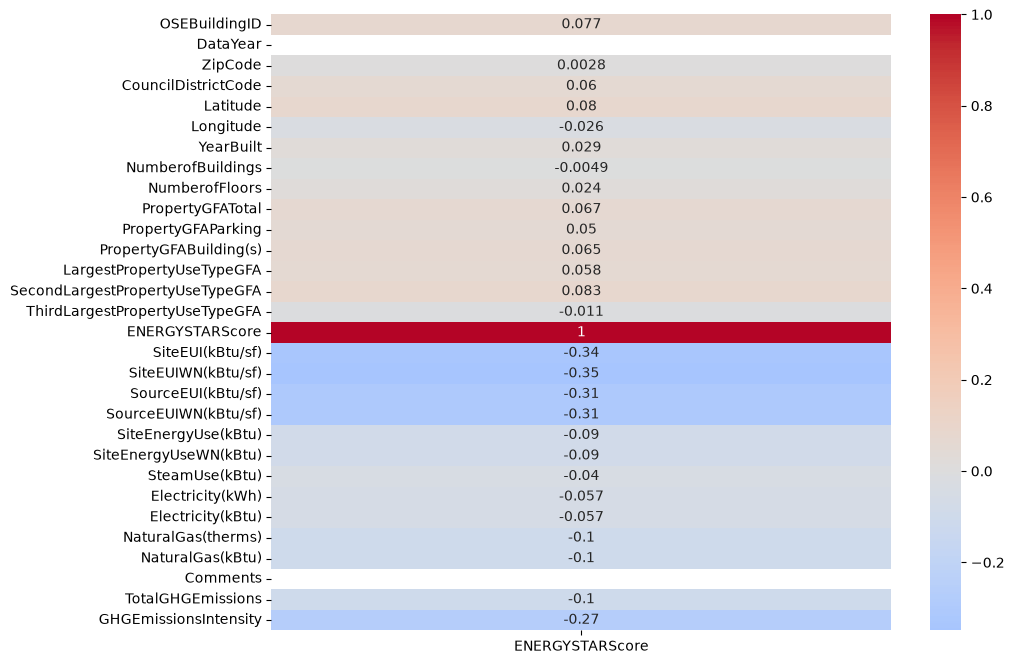

In [20]:
# détermination de la corrélation entre les colonnes numériques et le ENERGYSTARScore

corr_matrix = df.select_dtypes(include=['float64', 'int64']).corr()[['ENERGYSTARScore']]

# Visualisation de la corrélation
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)

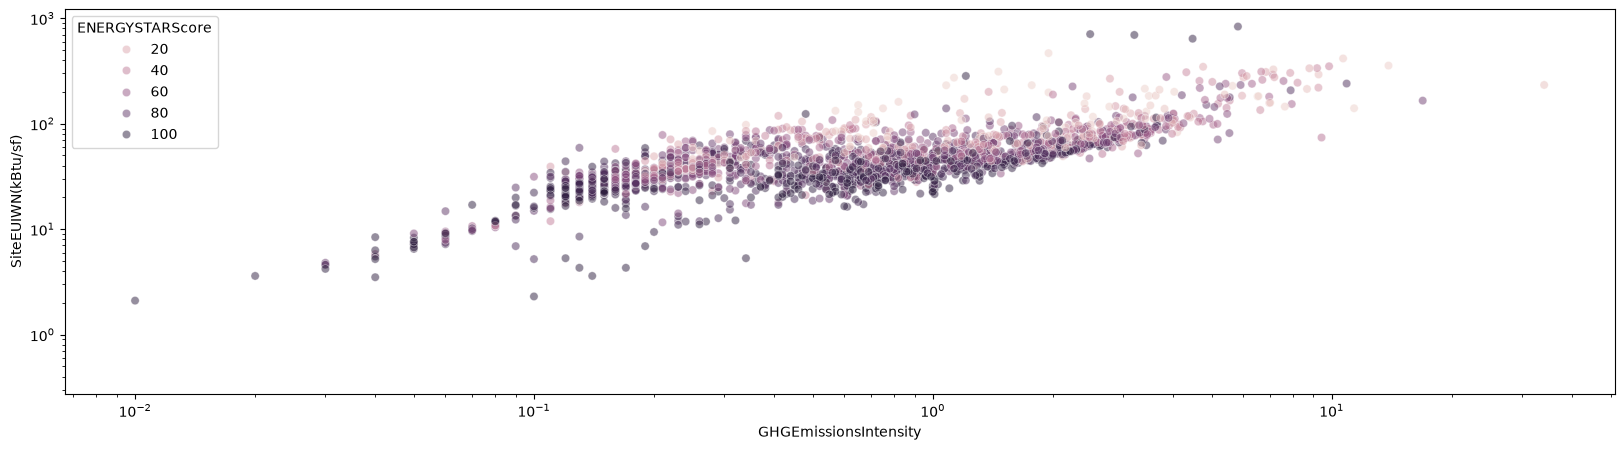

In [21]:
# visualisation du score ENERGYSTAR par rapport à l'énergie consommée et les émissions de GES

plt.figure(figsize=(20, 5))

sns.scatterplot(data=df, x='GHGEmissionsIntensity', y='SiteEUIWN(kBtu/sf)', hue='ENERGYSTARScore',alpha=0.5)
plt.xscale('log')
plt.yscale('log')

plt.show()

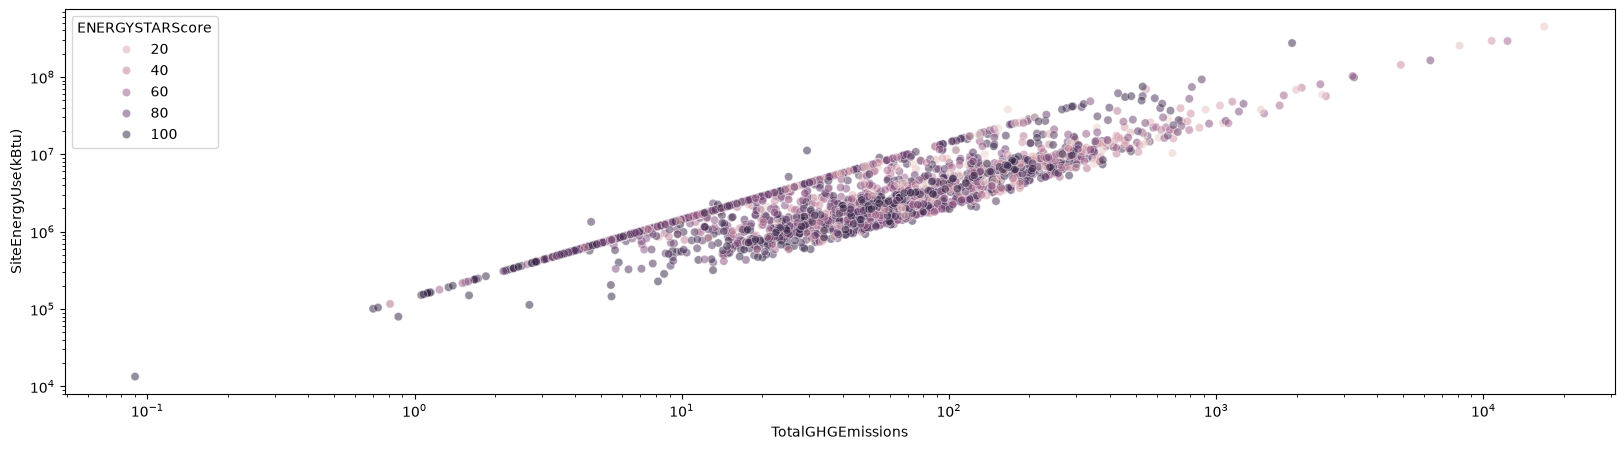

In [22]:
# visualisation du score ENERGYSTAR par rapport à l'énergie consommée et les émissions de GES

plt.figure(figsize=(20, 5))

sns.scatterplot(data=df_tri3, x='TotalGHGEmissions', y='SiteEnergyUse(kBtu)', hue='ENERGYSTARScore',alpha=0.5)
plt.xscale('log')
plt.yscale('log')

plt.show()

On voit une tendance par rapport à la notation ENERGYSTARScore, mais uniquement dans le cas de l'énergie et émissions par surface, et non pas par rapport à l'énergie et émissions totales. Sachant que nous estimons avoir accès aux données de surface, l'utilisation du ENERYSTARScore semble pertinant pour entrainer les modèles

# Nettoyage officiel

In [23]:
# Récupération des colonnes pertinentes pour l'analyse finale

df_clean = df[["BuildingType","PrimaryPropertyType","Latitude","Longitude","YearBuilt","NumberofBuildings","PropertyGFATotal","PropertyGFABuilding(s)","ListOfAllPropertyUseTypes",'LargestPropertyUseType', "LargestPropertyUseTypeGFA","SecondLargestPropertyUseType","SecondLargestPropertyUseTypeGFA","ThirdLargestPropertyUseType","ThirdLargestPropertyUseTypeGFA","SiteEnergyUse(kBtu)","ENERGYSTARScore","DefaultData","ComplianceStatus","Outlier","TotalGHGEmissions"]]

df_clean.head()

,BuildingType,PrimaryPropertyType,Latitude,Longitude,YearBuilt,NumberofBuildings,PropertyGFATotal,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,...,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),ENERGYSTARScore,DefaultData,ComplianceStatus,Outlier,TotalGHGEmissions
0,NonResidential,Hotel,47.61220,-122.33799,1927,1.0,88434,88434,Hotel,Hotel,...,NaN,NaN,NaN,NaN,7226362.5,60.0,False,Compliant,NaN,249.98
1,NonResidential,Hotel,47.61317,-122.33393,1996,1.0,103566,88502,"Hotel, Parking, Restaurant",Hotel,...,Parking,15064.0,Restaurant,4622.0,8387933.0,61.0,False,Compliant,NaN,295.86
2,NonResidential,Hotel,47.61393,-122.33810,1969,1.0,956110,759392,Hotel,Hotel,...,NaN,NaN,NaN,NaN,72587024.0,43.0,False,Compliant,NaN,2089.28
3,NonResidential,Hotel,47.61412,-122.33664,1926,1.0,61320,61320,Hotel,Hotel,...,NaN,NaN,NaN,NaN,6794584.0,56.0,False,Compliant,NaN,286.43
4,NonResidential,Hotel,47.61375,-122.34047,1980,1.0,175580,113580,"Hotel, Parking, Swimming Pool",Hotel,...,Parking,68009.0,Swimming Pool,0.0,14172606.0,75.0,False,Compliant,NaN,505.01


# Filtrage 

In [24]:
#BuildingType : Uniquement non-résidentiel
df_clean = df_clean[(df_clean['BuildingType'] == 'NonResidential')| (df_clean['BuildingType'] == 'SPS-District K-12') | (df_clean['BuildingType'] == 'Nonresidential COS') | (df_clean['BuildingType'] == 'Nonresidential WA') | (df_clean['BuildingType'] == 'Campus')]

#Outlier : supprimer High et Low Outlier
df_clean = df_clean[(df_clean['Outlier'] != 'High outlier')&(df_clean['Outlier'] != 'Low outlier')]

#Drop colonne Outlier
df_clean = df_clean.drop(columns=['Outlier'])

#DefaultData : Supprimer “True” 
df_clean = df_clean[df_clean['DefaultData'] != True]

#Drop colonne defaultData
df_clean = df_clean.drop(columns=['DefaultData'])

#Compliance Status : Supprimer “Missing Data” et “Error - Correction default data”
df_clean = df_clean[(df_clean['ComplianceStatus'] != 'Missing Data') & (df_clean['ComplianceStatus'] != 'Error - Correct Default Data')]

#SiteEnergyUse : Supprimer les lignes avec données manquantes
df_clean = df_clean[df_clean['SiteEnergyUse(kBtu)'].notna()]

#TotalGHGEmissions : Supprimer les lignes avec données manquantes
df_clean = df_clean[df_clean['TotalGHGEmissions'].notna()]

#Supprimer outliers consommation Energie (> 4.10^8)



df_clean.info()

<class 'pandas.DataFrame'>
Index: 1549 entries, 0 to 3375
Data columns (total 19 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   BuildingType                     1549 non-null   str    
 1   PrimaryPropertyType              1549 non-null   str    
 2   Latitude                         1549 non-null   float64
 3   Longitude                        1549 non-null   float64
 4   YearBuilt                        1549 non-null   int64  
 5   NumberofBuildings                1549 non-null   float64
 6   PropertyGFATotal                 1549 non-null   int64  
 7   PropertyGFABuilding(s)           1549 non-null   int64  
 8   ListOfAllPropertyUseTypes        1549 non-null   str    
 9   LargestPropertyUseType           1545 non-null   str    
 10  LargestPropertyUseTypeGFA        1545 non-null   float64
 11  SecondLargestPropertyUseType     843 non-null    str    
 12  SecondLargestPropertyUseTypeGFA  843

# Données manquantes

In [25]:
def remplir_nan_largest_property(df):
    liste = df['ListOfAllPropertyUseTypes']
    largest = df['LargestPropertyUseType']
    largest_from_list = liste.split(",")[0]
    
    if pd.isna(largest):
        return largest_from_list
    else:
        return largest
    
def remplir_nan_largest_property_surface(df):
    surface = df['LargestPropertyUseTypeGFA']
    surface_tot = df['PropertyGFATotal']
    
    if pd.isna(surface):
        return surface_tot
    else:
        return surface

In [ ]:
#LargestPropertyUseType : remplir les données manquantes par la première valeur de ListOfAllPropertyUseTypes
df_clean["LargestPropertyUseType"]= df_clean.apply(remplir_nan_largest_property, axis=1)

#transformer ListOfAllPropertyUseTypes en number of types
df_clean["ListOfAllPropertyUseTypes"] = df_clean["ListOfAllPropertyUseTypes"].apply(lambda x : len(x.split(",")))

#Energystarscore : remplir les données manquantes par le median ?
Energy_score_median = df_clean["ENERGYSTARScore"].median()
df_clean["ENERGYSTARScore"] = df_clean["ENERGYSTARScore"].fillna(Energy_score_median)

#SecondLargestPropertyUseTypeGFA/ThirdLargestPropertyUseTypeGFA : remplir données manquantes avec “0”
df_clean["SecondLargestPropertyUseTypeGFA"] = df_clean["SecondLargestPropertyUseTypeGFA"].fillna(0)
df_clean["ThirdLargestPropertyUseTypeGFA"] = df_clean["ThirdLargestPropertyUseTypeGFA"].fillna(0)

#SecondLargestPropertyUseType/ThirdLargestPropertyUseType: remplir données manquantes avec “NA” ?
df_clean["SecondLargestPropertyUseType"] = df_clean["SecondLargestPropertyUseType"].fillna("NA")
df_clean["ThirdLargestPropertyUseType"] = df_clean["ThirdLargestPropertyUseType"].fillna("NA")

#LargestPropertyUseTypeGFA : remplir les données manquantes par PropertyGFATotal
df_clean["LargestPropertyUseTypeGFA"] = df_clean.apply(remplir_nan_largest_property_surface, axis=1)

#Supprimer outliers consommation Energie (> 10^8)
df_clean = df_clean[df_clean["SiteEnergyUse(kBtu)"]<=100000000]

#encoder LargestPropertyUseType / secondLargestPropertyUseType / ThirdLargestPropertyUseType / PrimaryPropertyType / ComplianceStatus / BuildingType

df_clean.info()

<class 'pandas.DataFrame'>
Index: 1538 entries, 0 to 3375
Data columns (total 19 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   BuildingType                     1538 non-null   str    
 1   PrimaryPropertyType              1538 non-null   str    
 2   Latitude                         1538 non-null   float64
 3   Longitude                        1538 non-null   float64
 4   YearBuilt                        1538 non-null   int64  
 5   NumberofBuildings                1538 non-null   float64
 6   PropertyGFATotal                 1538 non-null   int64  
 7   PropertyGFABuilding(s)           1538 non-null   int64  
 8   ListOfAllPropertyUseTypes        1538 non-null   int64  
 9   LargestPropertyUseType           1538 non-null   str    
 10  LargestPropertyUseTypeGFA        1538 non-null   float64
 11  SecondLargestPropertyUseType     1538 non-null   str    
 12  SecondLargestPropertyUseTypeGFA  153

In [27]:
df_clean["PrimaryPropertyType"].value_counts()

PrimaryPropertyType
Small- and Mid-Sized Office    286
Other                          244
Warehouse                      185
Large Office                   169
Mixed Use Property             112
Retail Store                    85
Hotel                           75
Worship Facility                69
Distribution Center             53
K-12 School                     50
Supermarket / Grocery Store     40
Medical Office                  38
Self-Storage Facility           28
University                      22
Residence Hall                  21
Senior Care Community           20
Refrigerated Warehouse          12
Restaurant                      12
Laboratory                      10
Hospital                         5
Low-Rise Multifamily             2
Name: count, dtype: int64

In [28]:
# Supprimer mes "Low-Rise Multifamily dans la colonne PrimaryPropertyType
df_clean = df_clean[df_clean["PrimaryPropertyType"]!= "Low-Rise Multifamily"]

# Encoder les colonnes en string

# Visualisations du dataset nettoyé

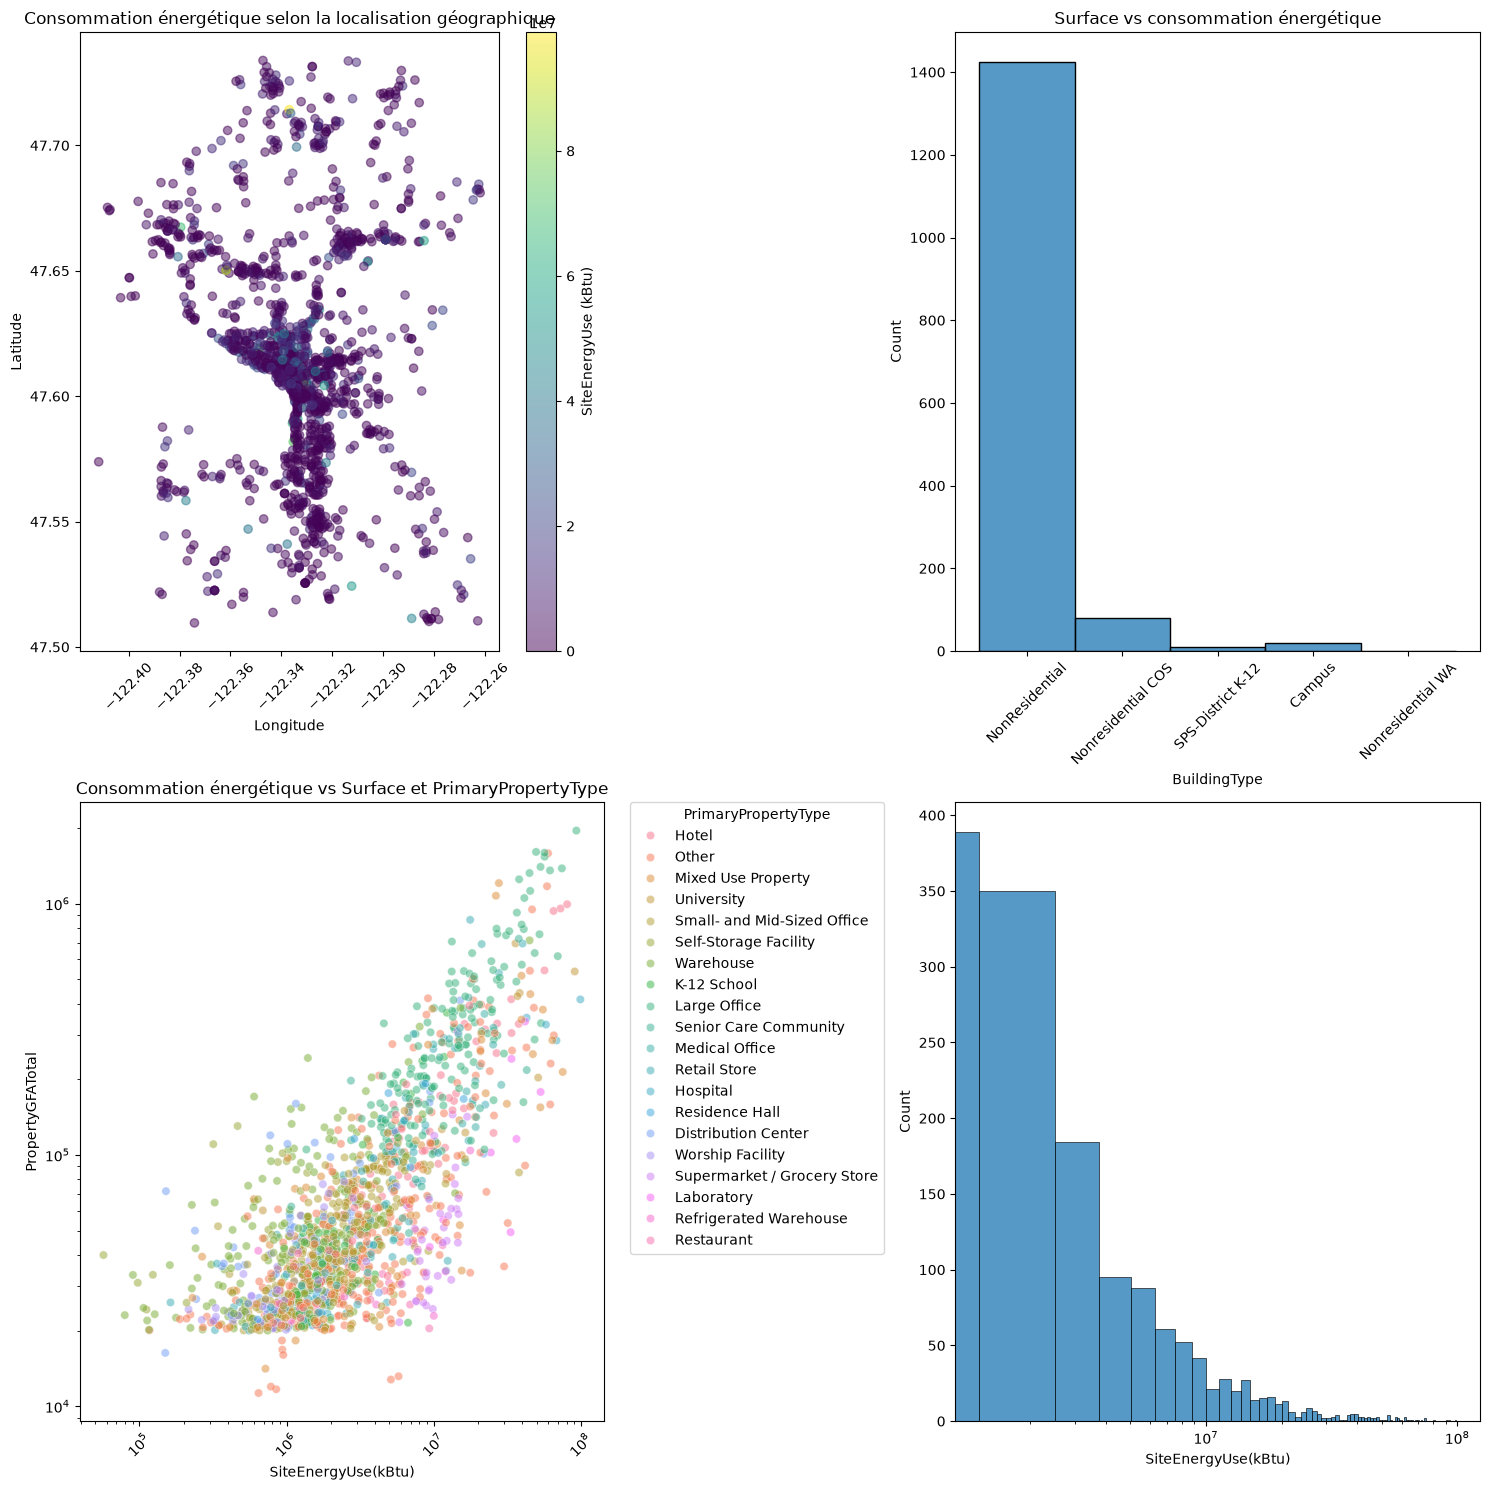

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(15, 15))

# Graphique 1 : Consommation énergétique selon la localisation géographique

scatter = axes[0, 0].scatter(
    df_clean['Longitude'],
    df_clean['Latitude'],
    c=df_clean['SiteEnergyUse(kBtu)'],
    cmap='viridis',
    alpha=0.5
)

# Barre de couleur continue
fig.colorbar(
    scatter,
    ax=axes[0, 0],
    label='SiteEnergyUse (kBtu)'
)

axes[0, 0].set_title('Consommation énergétique selon la localisation géographique')
axes[0, 0].set_xlabel('Longitude')
axes[0, 0].set_ylabel('Latitude')

# Graphique 2 : Distribution des building types
sns.histplot(
    data=df_clean,
    x='BuildingType',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Building types')
axes[0, 1].set_title('Surface vs consommation énergétique')

# Graphique 3 : Energie, surface et Type de batiment
sns.scatterplot(
    data=df_clean,
    x='SiteEnergyUse(kBtu)',
    y='PropertyGFATotal',
    hue = 'PrimaryPropertyType',
    ax=axes[1, 0],
    alpha=0.5
)
axes[1, 0].set_xscale('log')
axes[1, 0].set_yscale('log')
axes[1, 0].set_title('Consommation énergétique vs Surface et PrimaryPropertyType')
axes[1, 0].legend(title='PrimaryPropertyType',bbox_to_anchor=(1.05, 1),loc='upper left',borderaxespad=0)

# Graphique 4 : Energie, surface et Type de batiment
sns.histplot(
    data=df_clean,
    x='SiteEnergyUse(kBtu)',
    ax=axes[1, 1]
)
axes[1, 1].set_xscale('log')

axes[0, 0].tick_params(axis='x', labelrotation=45)
axes[0, 1].tick_params(axis='x', labelrotation=45)
axes[1, 0].tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()

In [30]:
df_clean["ComplianceStatus"].value_counts()

ComplianceStatus
Compliant        1535
Non-Compliant       1
Name: count, dtype: int64

Text(0.5, 1.0, 'Moyenne des Emissions GES par ListOfAllPropertyUseTypes')

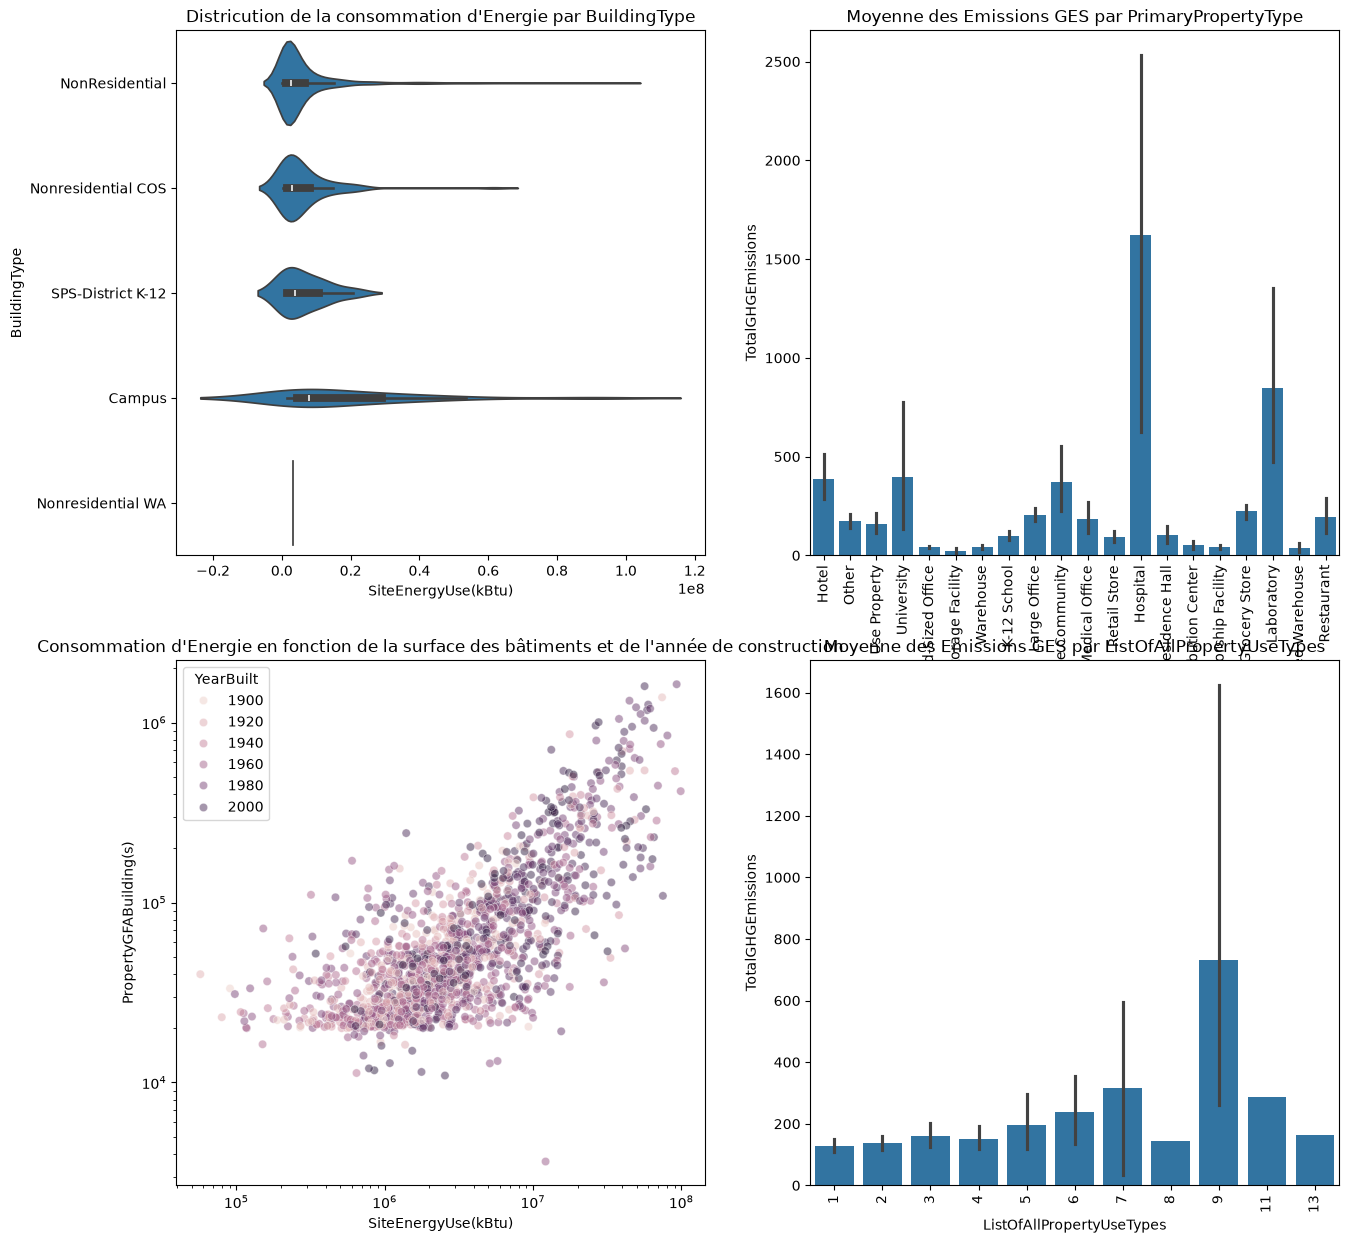

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(15, 15))

sns.violinplot(data=df_clean, x = 'SiteEnergyUse(kBtu)' , y= 'BuildingType', ax=axes[0, 0] )
axes[0,0].set_title("Districution de la consommation d'Energie par BuildingType")

sns.barplot(data=df_clean, x = 'PrimaryPropertyType' , y = 'TotalGHGEmissions', ax=axes[0, 1] )
axes[0, 1].tick_params(axis='x', labelrotation=90)
axes[0,1].set_title("Moyenne des Emissions GES par PrimaryPropertyType")

sns.scatterplot(data=df_clean, x = 'SiteEnergyUse(kBtu)' , y = 'PropertyGFABuilding(s)', hue = 'YearBuilt', alpha = 0.5, ax=axes[1,0])
axes[1,0].set_title("Consommation d'Energie en fonction de la surface des bâtiments et de l'année de construction")
axes[1,0].set_xscale('log')
axes[1,0].set_yscale('log')

sns.barplot(data=df_clean, x = 'ListOfAllPropertyUseTypes' , y = 'TotalGHGEmissions', ax=axes[1, 1] )
axes[1, 1].tick_params(axis='x', labelrotation=90)
axes[1,1].set_title("Moyenne des Emissions GES par ListOfAllPropertyUseTypes")


Latitude / longitude ne semblent pas être correlé avec l'Energie et les Emissions

Compliancestatus : seulement 1 non-compliant --> colonne avec peu d'intérêt après le filtage initial
